# 03. 과거 거래 5개 구간 × 동일 분 활동 — 정상 vs 무패턴

**비교 기간: 2022년 8월 8일 이상 ~ 11월 6일 미만(11월 5일 23:59까지).** 정상·무패턴에 동일한 날짜 조건을 적용합니다. 기존 출력에서는 무패턴은 11월 5일까지, 정상은 11월 30일까지 있어 비교 기간이 달랐습니다.

기본 설정은 **이미 완료한 03번 피처를 재사용하여 표·그림만 다시 집계**합니다. 과거 이력, 금액 z, 동일 분 활동을 다시 계산하지 않습니다. 전체 기간 실행 결과는 `results/03_pair_bins_same_minute_full_period.ipynb`에 보관했습니다. 이 노트북의 이전 출력은 새 기간 결과와 혼동하지 않도록 비웠습니다.

필요한 파일(기본 재사용 모드):
- `parquets/HI-Large/nonpaten_vs_normal/pair_bins_same_minute_v1/features.parquet`
- 같은 폴더의 `analysis_summary.json`

별도 Python 파일 없이 이 노트북 하나로 실행할 수 있습니다. **GPU 서버 Jupyter**에서 위에서 아래로 실행하세요. CPU RAM·디스크를 사용하며 전체 거래를 pandas로 로딩하지 않습니다.

처음부터 동일 분 피처를 만들어야 하는 경우만 `REUSE_EXISTING_FEATURES = False`로 바꿉니다. 그때는 전체 `transactions.parquet`와 02번의 `features.parquet`, `analysis_summary.json`도 필요합니다. 이 모드에서도 최종 표·그림은 위 비교 기간으로 제한됩니다.

## 1. 비교 기준

과거 이력은 현재 분보다 이른 거래만 포함하며 기존 값을 수정하지 않습니다. `pair_prior_n`을 **0 / 1 / 2~5 / 6~20 / 21건 이상**으로 분류합니다. 구간별 무패턴 비율은 **무패턴 / (정상 + 무패턴)**이며 패턴 양성은 분모에 없습니다. 빈 구간은 비율을 NULL로 둡니다.

| 추가 피처 | 현재 거래 A → B를 기준으로 한 정의 |
|---|---|
| `pair_same_minute_other_n` | 같은 분 A → B의 다른 거래 수 |
| `receiver_same_minute_other_in_n` | 같은 분 B가 받은 다른 입금 수 |
| `receiver_same_minute_other_in_neighbors` | 현재 거래를 제외한 같은 분 입금의 고유 송신 계좌 수. 다른 A → B가 남으면 A도 포함 |
| `receiver_same_minute_other_out_n` | 같은 분 B가 보낸 출금 수. 현재 거래가 B → B일 때만 현재 건을 차감 |

**동일 분 활동은 그 분이 끝난 후 알 수 있는 정보**입니다. 거래 직전의 과거 이력으로 합치거나 실시간 입력으로 해석하지 않습니다. 같은 분 거래의 실제 순서를 `edge_id`로 추정하지 않습니다. 이후 분의 거래는 포함하지 않습니다. 자기 이체는 입금·출금 양쪽에서 현재 거래 자신을 제외합니다.

금액 z와 직전 입금 간격도 02번 값을 그대로 사용합니다. 과거 입금이 없는 거래의 간격 NULL을 0분으로 바꾸지 않습니다. 정상·패턴·무패턴 라벨은 동일 분 건수 계산에 사용하지 않습니다.

In [1]:
# 패키지가 없을 때만 실행
# %pip install duckdb pandas numpy matplotlib

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import json
import shutil
import duckdb
import pandas as pd
from IPython.display import display

PROJECT_ROOT = None  # 예: Path('/workspace/money_laundry_ai_')
REUSE_EXISTING_FEATURES = True  # 이미 실행한 03번 피처로 재집계 (기본값)
EXISTING_RUN = 'pair_bins_same_minute_v1'  # 완료한 03번 결과
SOURCE_RUN = 'pair_history_pit_v1'        # 새로 계산할 때만 쓰는 02번 결과
ANALYSIS_START = '2022-08-08'
ANALYSIS_END_EXCLUSIVE = '2022-11-06'     # 정상·무패턴 모두 11월 5일까지
RUN_TAG = 'pair_bins_same_minute_until_1105'  # 기존 결과와 별도 저장
THREADS = 4
MEMORY = '6GB'
KEEP_WORK_DB = False

for value in [SOURCE_RUN, EXISTING_RUN, RUN_TAG]:
    if not value or value in ('.','..') or '/' in value or '\\' in value:
        raise ValueError('실행 이름에는 폴더 이름 하나만 지정하세요.')
if PROJECT_ROOT is None:
    here = Path.cwd().resolve()
    search_file = (Path('parquets/HI-Large/nonpaten_vs_normal')/EXISTING_RUN/'features.parquet'
                   if REUSE_EXISTING_FEATURES else Path('parquets/HI-Large/transactions.parquet'))
    ROOT = next((p for p in [here, *here.parents] if (p/search_file).is_file()), None)
    if ROOT is None:
        raise FileNotFoundError('입력 피처를 찾지 못했습니다. PROJECT_ROOT와 EXISTING_RUN을 확인하세요.')
else:
    ROOT = Path(PROJECT_ROOT).expanduser().resolve()
BASE = ROOT/'parquets/HI-Large'
TX_PATH = BASE/'transactions.parquet'
SOURCE_DIR = BASE/'nonpaten_vs_normal'/SOURCE_RUN
BASE_FEATURES = SOURCE_DIR/'features.parquet'
SOURCE_SUMMARY = SOURCE_DIR/'analysis_summary.json'
EXISTING_DIR = BASE/'nonpaten_vs_normal'/EXISTING_RUN
EXISTING_FEATURES = EXISTING_DIR/'features.parquet'
EXISTING_SUMMARY = EXISTING_DIR/'analysis_summary.json'
OUT = BASE/'nonpaten_vs_normal'/RUN_TAG
if OUT.resolve() in [SOURCE_DIR.resolve(), EXISTING_DIR.resolve()]:
    raise ValueError('결과 폴더는 기존 02·03번 폴더와 달라야 합니다.')
WORK = OUT/'work.duckdb'
FEATURES = EXISTING_FEATURES if REUSE_EXISTING_FEATURES else OUT/'features.parquet'
print('실행 모드:', '기존 03 피처 재집계' if REUSE_EXISTING_FEATURES else '피처 생성 후 기간 제한 집계')
print('사용할 피처:', FEATURES)
print('분석 기간:', ANALYSIS_START, '이상 ~', ANALYSIS_END_EXCLUSIVE, '미만')
print('새 결과:', OUT)
print(f'여유 디스크: {shutil.disk_usage(ROOT).free/2**30:,.1f} GiB')

실행 모드: 기존 03 피처 재집계
사용할 피처: /workspace/money_laundry_ai_/parquets/HI-Large/nonpaten_vs_normal/pair_bins_same_minute_v1/features.parquet
분석 기간: 2022-08-08 이상 ~ 2022-11-06 미만
새 결과: /workspace/money_laundry_ai_/parquets/HI-Large/nonpaten_vs_normal/pair_bins_same_minute_until_1105
여유 디스크: 199.6 GiB


## 2. 계산 함수

아래 셀은 함수 정의만 합니다. 기본 재사용 모드에서는 날짜 조건으로 대상 거래만 선택하고 기존 피처 값은 보존합니다. 새 피처 생성 모드에서만 전체 원장과 거래 ID·값을 대조하고 동일 분 활동을 계산합니다. 건수는 정확 집계, 분위수는 근사값입니다.

In [3]:
"""03 notebook implementation; embedded in the notebook for standalone use."""
from pathlib import Path
from datetime import datetime
import time
import pandas as pd

BUCKETS = ['0', '1', '2~5', '6~20', '21+']
MINUTE_METRICS = [
    'pair_same_minute_other_n', 'receiver_same_minute_other_in_n',
    'receiver_same_minute_other_in_neighbors', 'receiver_same_minute_other_out_n',
]
METRICS = ['pair_prior_n', 'paid_currency_z', 'amt_z_pay_ccy',
           'receiver_in_gap_minutes', 'receiver_in_count'] + MINUTE_METRICS


def q(value):
    return "'" + str(value).replace("'", "''") + "'"


def require(ok, message):
    if not ok:
        raise ValueError(message)


def run(con, title, sql):
    print(title, flush=True)
    started = time.perf_counter()
    con.execute(sql)
    print(f'  완료: {time.perf_counter()-started:,.1f}초', flush=True)


def bucket_sql(column):
    return (f"CASE WHEN {column}=0 THEN 0 WHEN {column}=1 THEN 1 "
            f"WHEN {column}<=5 THEN 2 WHEN {column}<=20 THEN 3 ELSE 4 END")


def extend_features(con, transactions, base_features, destination):
    """Preserve every base column; minute features use all labels, excluding self row.

    Both inputs must come from the same 02 run and original ledger. Validate target
    identity against the ledger before subtracting one from minute counts.
    """
    destination = Path(destination)
    require(not destination.exists(), f'기존 결과가 있습니다: {destination}')
    for p in [transactions, base_features]:
        require(Path(p).is_file(), f'입력 파일 없음: {p}')
    con.execute(f'CREATE OR REPLACE VIEW base AS SELECT * FROM read_parquet({q(base_features)})')
    con.execute(f'CREATE OR REPLACE VIEW ledger AS SELECT * FROM read_parquet({q(transactions)})')
    columns = {r[0] for r in con.execute('DESCRIBE base').fetchall()}
    required = {'edge_id','ts','src','dst','class_name','is_laundering','payment_currency',
                'payment_format','paid','pair_prior_n','paid_currency_z','amt_z_pay_ccy',
                'receiver_in_gap_minutes','receiver_in_count'}
    require(required <= columns, f'02 피처 컬럼 누락: {required-columns}')
    require(not (set(MINUTE_METRICS) | {'prior_bucket','prior_bucket_order'}) & columns,
            '이미 확장된 피처 대신 02번 features.parquet를 지정하세요.')
    n, unique_n, first, last, bad = con.execute("""
        SELECT count(*),count(DISTINCT edge_id),min(ts),max(ts),
          count(*) FILTER (WHERE ts IS NULL OR src IS NULL OR dst IS NULL
            OR ts IS DISTINCT FROM date_trunc('minute',ts)
            OR pair_prior_n IS NULL OR NOT isfinite(pair_prior_n)
            OR pair_prior_n<0 OR pair_prior_n<>floor(pair_prior_n)
            OR is_laundering IS NULL OR class_name IS DISTINCT FROM
              CASE WHEN is_laundering THEN 'nonpattern' ELSE 'normal' END)
        FROM base
    """).fetchone()
    require(n > 0 and n == unique_n and bad == 0, '02 피처의 ID·분 시각·이력 건수·라벨 오류')
    # Materialize only the target period; same-minute activity needs no older rows.
    # No class filter: known-pattern transactions remain in this table.
    run(con, '동일 분 집계용 전체 원장 준비 (패턴 거래 포함)', f"""
        CREATE OR REPLACE TABLE minute_source AS
        SELECT edge_id,ts,src,dst,paid,payment_currency,payment_format,is_laundering
        FROM ledger WHERE ts >= TIMESTAMP {q(first)} AND ts <= TIMESTAMP {q(last)}
    """)
    source_n, source_unique, source_bad = con.execute("""
        SELECT count(*),count(DISTINCT edge_id),count(*) FILTER (
          WHERE ts IS NULL OR src IS NULL OR dst IS NULL
            OR ts IS DISTINCT FROM date_trunc('minute',ts)) FROM minute_source
    """).fetchone()
    require(source_n == source_unique and source_bad == 0, '원장의 중복 ID·분 시각·계좌 오류')
    print('02 피처와 전체 원장의 거래 ID·값 일치 검사', flush=True)
    joined, mismatch = con.execute("""
        SELECT count(*),count(*) FILTER (WHERE t.edge_id IS NULL
          OR f.ts IS DISTINCT FROM t.ts OR f.src IS DISTINCT FROM t.src
          OR f.dst IS DISTINCT FROM t.dst OR f.paid IS DISTINCT FROM t.paid
          OR f.payment_currency IS DISTINCT FROM t.payment_currency
          OR f.payment_format IS DISTINCT FROM t.payment_format
          OR f.is_laundering IS DISTINCT FROM t.is_laundering)
        FROM base f LEFT JOIN minute_source t ON f.edge_id=t.edge_id
    """).fetchone()
    require(joined == n and mismatch == 0, '02 피처와 원장이 다른 실행 또는 다른 거래입니다.')
    run(con, '동일 분의 계좌쌍 및 수신 계좌 활동 집계', """
        CREATE OR REPLACE TABLE minute_pairs AS
        SELECT src,dst,ts,count(*)::BIGINT AS n
        FROM minute_source GROUP BY src,dst,ts;
        CREATE OR REPLACE TABLE minute_in AS
        SELECT dst,ts,sum(n)::BIGINT AS n,count(*)::BIGINT AS neighbors
        FROM minute_pairs GROUP BY dst,ts;
        CREATE OR REPLACE TABLE minute_out AS
        SELECT src,ts,sum(n)::BIGINT AS n FROM minute_pairs GROUP BY src,ts;
        DROP TABLE minute_source;
    """)
    run(con, '기존 과거 피처를 보존하고 동일 분 활동 저장', f"""
        COPY (
          SELECT f.*,{bucket_sql('f.pair_prior_n')} AS prior_bucket_order,
            CASE {bucket_sql('f.pair_prior_n')}
              WHEN 0 THEN '0' WHEN 1 THEN '1' WHEN 2 THEN '2~5'
              WHEN 3 THEN '6~20' ELSE '21+' END AS prior_bucket,
            p.n-1 AS pair_same_minute_other_n,
            i.n-1 AS receiver_same_minute_other_in_n,
            i.neighbors-CASE WHEN p.n=1 THEN 1 ELSE 0 END
              AS receiver_same_minute_other_in_neighbors,
            coalesce(o.n,0)-CASE WHEN f.src=f.dst THEN 1 ELSE 0 END
              AS receiver_same_minute_other_out_n
          FROM base f
          JOIN minute_pairs p ON f.src=p.src AND f.dst=p.dst AND f.ts=p.ts
          JOIN minute_in i ON f.dst=i.dst AND f.ts=i.ts
          LEFT JOIN minute_out o ON f.dst=o.src AND f.ts=o.ts
        ) TO {q(destination)} (FORMAT PARQUET,COMPRESSION ZSTD)
    """)
    con.execute(f'CREATE OR REPLACE VIEW extended AS SELECT * FROM read_parquet({q(destination)})')
    invalid = ' OR '.join(f'{m} IS NULL OR {m}<0' for m in MINUTE_METRICS)
    written, bad = con.execute(f"""
        SELECT count(*),count(*) FILTER (WHERE {invalid}
          OR pair_same_minute_other_n>receiver_same_minute_other_in_n
          OR receiver_same_minute_other_in_neighbors>receiver_same_minute_other_in_n)
        FROM extended
    """).fetchone()
    require(written == n and bad == 0, '추가 피처의 건수 보존·비음수 검사 실패')
    return dict(feature_rows=n, minute_source_rows=source_n,
                analysis_first=str(first), analysis_last=str(last),
                target_identity_mismatches=mismatch, invalid_feature_rows=bad)


def select_analysis_period(con, features, start, end_exclusive):
    """Filter target rows only; keep original historical/minute features unchanged."""
    start_ts, end_ts = map(datetime.fromisoformat, (start, end_exclusive))
    require(start_ts < end_ts, '분석 시작은 종료보다 빨라야 합니다.')
    require(all(t.second == 0 and t.microsecond == 0 for t in [start_ts, end_ts]),
            '동일 분 활동을 보존하도록 분석 경계를 분 단위로 지정하세요.')
    require(Path(features).is_file(), f'피처 파일 없음: {features}')
    con.execute(f"""
        CREATE OR REPLACE VIEW extended AS
        SELECT * FROM read_parquet({q(features)})
        WHERE ts >= TIMESTAMP {q(start)} AND ts < TIMESTAMP {q(end_exclusive)}
    """)
    n, normal, nonpattern, first, last = con.execute("""
        SELECT count(*),count(*) FILTER (WHERE class_name='normal'),
          count(*) FILTER (WHERE class_name='nonpattern'),min(ts),max(ts)
        FROM extended
    """).fetchone()
    require(n > 0 and normal > 0 and nonpattern > 0 and n == normal+nonpattern,
            '선택한 기간에 정상과 무패턴이 모두 있어야 하며 다른 클래스는 없어야 합니다.')
    return dict(analysis_start=start, analysis_end_exclusive=end_exclusive,
                analysis_rows=n, normal_rows=normal, nonpattern_rows=nonpattern,
                analysis_first=str(first), analysis_last=str(last))


def summarize(con, output):
    output = Path(output)
    tables = {}
    # Include empty prior bins. Empty denominators are NULL, never a zero fraud rate.
    tables['bucket_rates'] = con.execute("""
        WITH bins AS (SELECT * FROM (VALUES (0,'0'),(1,'1'),(2,'2~5'),
          (3,'6~20'),(4,'21+')) v(prior_bucket_order,prior_bucket)),
        counts AS (SELECT prior_bucket_order,
          count(*) FILTER (WHERE class_name='normal') AS normal_n,
          count(*) FILTER (WHERE class_name='nonpattern') AS nonpattern_n
          FROM extended GROUP BY 1)
        SELECT b.*,coalesce(normal_n,0) AS normal_n,coalesce(nonpattern_n,0) AS nonpattern_n,
          coalesce(normal_n,0)+coalesce(nonpattern_n,0) AS total_n,
          nonpattern_n::DOUBLE/nullif(normal_n+nonpattern_n,0) AS nonpattern_rate,
          normal_n::DOUBLE/nullif(sum(normal_n) OVER (),0) AS share_within_normal,
          nonpattern_n::DOUBLE/nullif(sum(nonpattern_n) OVER (),0) AS share_within_nonpattern
        FROM bins b LEFT JOIN counts USING(prior_bucket_order) ORDER BY 1
    """).df()
    for name, dims in [
        ('monthly_bucket_rates', "strftime(ts,'%Y-%m') AS month,prior_bucket_order,prior_bucket"),
        ('currency_format_bucket_rates', 'payment_currency,payment_format,prior_bucket_order,prior_bucket'),
    ]:
        tables[name] = con.execute(f"""
            SELECT {dims},count(*) AS total_n,
              count(*) FILTER (WHERE class_name='normal') AS normal_n,
              count(*) FILTER (WHERE class_name='nonpattern') AS nonpattern_n,
              avg((class_name='nonpattern')::INT) AS nonpattern_rate
            FROM extended GROUP BY ALL ORDER BY ALL
        """).df()
    tables['monthly_coverage'] = con.execute("""
        SELECT strftime(ts,'%Y-%m') AS month,class_name,count(*) AS n,
          min(ts) AS first_ts,max(ts) AS last_ts,
          count(DISTINCT CAST(ts AS DATE)) AS observed_days
        FROM extended GROUP BY 1,2 ORDER BY 1,2
    """).df()
    # Count-only cross tables let us compare same-minute activity within a prior bin.
    parts = []
    for m in MINUTE_METRICS:
        parts.append(f"""SELECT prior_bucket_order,prior_bucket,{q(m)} AS feature,
          {bucket_sql(m)} AS activity_bucket_order,
          count(*) AS total_n,count(*) FILTER (WHERE class_name='normal') AS normal_n,
          count(*) FILTER (WHERE class_name='nonpattern') AS nonpattern_n,
          avg((class_name='nonpattern')::INT) AS nonpattern_rate
          FROM extended GROUP BY 1,2,3,4""")
    tables['same_minute_rates'] = con.execute(' UNION ALL '.join(parts)+' ORDER BY 1,3,4').df()
    tables['same_minute_rates']['activity_bucket'] = tables['same_minute_rates'].activity_bucket_order.map(dict(enumerate(BUCKETS)))
    # Nulls remain missing; no-history gaps are not converted to zero.
    for name, dims, metrics in [
        ('feature_summary', ['prior_bucket_order','prior_bucket','class_name'], METRICS),
        ('monthly_feature_summary', ["strftime(ts,'%Y-%m') AS month",'prior_bucket_order','prior_bucket','class_name'], METRICS[:5]),
        ('currency_format_feature_summary', ['payment_currency','payment_format','prior_bucket_order','prior_bucket','class_name'], ['paid_currency_z','amt_z_pay_ccy','receiver_in_gap_minutes']),
    ]:
        print(f'분포 집계: {name}', flush=True)
        expressions = []
        for m in metrics:
            expressions += [f'count({m}) AS {m}__valid',f'avg({m}) AS {m}__mean',
                            f'count(*) FILTER (WHERE {m}=0) AS {m}__zeros',
                            f'approx_quantile({m},[.1,.25,.5,.75,.9,.99]) AS {m}__q']
        wide = con.execute('SELECT '+','.join(dims)+',count(*) AS n,'+','.join(expressions)+
                           ' FROM extended GROUP BY ALL ORDER BY ALL').df()
        records = []
        keys = [d.split(' AS ')[-1] for d in dims]
        for _, row in wide.iterrows():
            for m in metrics:
                valid = int(row[m+'__valid'])
                quantiles = row[m+'__q'] if valid else [None]*6
                records.append({**{k:row[k] for k in keys},'feature':m,'n':int(row.n),
                    'valid_n':valid,'missing_n':int(row.n)-valid,'mean':row[m+'__mean'],
                    'zero_rate_valid':row[m+'__zeros']/valid if valid else None,
                    **dict(zip(['p10','p25','p50','p75','p90','p99'],quantiles))})
        tables[name] = pd.DataFrame(records)
    for name, df in tables.items():
        df.to_csv(output/f'{name}.csv',index=False,encoding='utf-8-sig')
    return tables


def plot_results(tables, output):
    import numpy as np
    import matplotlib.pyplot as plt
    output = Path(output)
    df = tables['bucket_rates'].set_index('prior_bucket').reindex(BUCKETS)
    fig, ax = plt.subplots(figsize=(8,4))
    ax.bar(BUCKETS,df.nonpattern_rate*100)
    ax.set(xlabel='Prior same-direction pair count',ylabel='Nonpattern / (normal + nonpattern), %')
    fig.tight_layout();fig.savefig(output/'bucket_nonpattern_rate.png',dpi=150)
    plt.show();plt.close(fig)
    stats = tables['feature_summary']
    for filename, metrics in [('amount_gap_by_bucket',['paid_currency_z','amt_z_pay_ccy','receiver_in_gap_minutes']),
                              ('same_minute_by_bucket',MINUTE_METRICS)]:
        fig, axes = plt.subplots(1,len(metrics),figsize=(5*len(metrics),4),squeeze=False)
        for ax,m in zip(axes.flat,metrics):
            for offset,cl in [(-.12,'normal'),(.12,'nonpattern')]:
                part = stats[(stats.feature==m)&(stats.class_name==cl)].set_index('prior_bucket').reindex(BUCKETS)
                med = part.p50.to_numpy(float)
                ax.errorbar(np.arange(5)+offset,med,
                    yerr=[np.maximum(0,med-part.p25.to_numpy(float)),np.maximum(0,part.p75.to_numpy(float)-med)],
                    fmt='o',capsize=3,label=cl)
            ax.set_xticks(range(5),BUCKETS);ax.set_title(m,fontsize=9);ax.legend()
            ax.set_xlabel('Prior pair count');ax.set_ylabel('Median and p25-p75 (approx.)')
            if m not in ['paid_currency_z','amt_z_pay_ccy']:ax.set_yscale('symlog',linthresh=1)
        fig.tight_layout();fig.savefig(output/f'{filename}.png',dpi=150)
        plt.show();plt.close(fig)


## 3. 동일 기간 재집계 및 저장

**기본 모드에서는 오래 걸리는 원장 조인·동일 분 피처 생성을 건너뜁니다.** 기존 03번 결과 파일을 읽어 정상·무패턴 모두 `2022-08-08 <= ts < 2022-11-06` 조건을 적용합니다. 과거 이력은 분석 시작 전의 거래도 포함한 기존 값 그대로입니다.

11월 1~5일을 두 집단에 공통으로 적용했는지 먼저 출력하고, 이후 모든 CSV·그림에 같은 필터를 사용합니다. 새 결과 폴더가 비어 있지 않으면 중단하므로 재실행하려면 `RUN_TAG`를 바꾸세요. 입력과 이전 결과는 덮어쓰지 않습니다. 성공한 경우에만 작업 DB를 정리합니다.

In [4]:
if REUSE_EXISTING_FEATURES:
    input_paths = [EXISTING_FEATURES, EXISTING_SUMMARY]
else:
    input_paths = [TX_PATH, BASE_FEATURES, SOURCE_SUMMARY]
for path in input_paths:
    require(path.is_file(), f'필요한 파일이 없습니다: {path}')
summary_path = EXISTING_SUMMARY if REUSE_EXISTING_FEATURES else SOURCE_SUMMARY
source_audit = json.loads(summary_path.read_text(encoding='utf-8-sig'))
require(source_audit.get('status') == 'features_and_tables_complete',
        '피처 생성이 완료된 원본 실행의 analysis_summary.json을 지정하세요.')
if REUSE_EXISTING_FEATURES:
    require(source_audit.get('prior_policy') == '02 features unchanged; strictly before target minute',
            '기존 03번 피처의 과거 이력 정책이 다릅니다.')
    require(source_audit.get('same_minute_policy') ==
            'all labels including patterns; exclude current edge; end-of-minute only',
            '기존 03번 피처의 동일 분 집계 정책이 다릅니다.')
else:
    require(source_audit.get('history_policy') ==
            'all observed transactions including patterns, strictly before target minute',
            '02번 과거 이력 정책이 예상과 다릅니다.')
    source_tx = [v for k,v in source_audit.get('inputs', {}).items()
                 if k.replace('\\','/').split('/')[-1] == 'transactions.parquet']
    require(len(source_tx)==1 and source_tx[0]['bytes']==TX_PATH.stat().st_size,
            '02번에서 사용한 전체 원장 파일과 크기가 다릅니다.')
require(not OUT.exists() or not any(OUT.iterdir()),
        f'기존 결과가 있습니다. RUN_TAG를 바꾸세요: {OUT}')
OUT.mkdir(parents=True, exist_ok=True)
spill = OUT/'duckdb_tmp'
spill.mkdir(exist_ok=True)
input_state = {str(p): {'bytes':p.stat().st_size, 'mtime_ns':p.stat().st_mtime_ns}
               for p in input_paths}
con = duckdb.connect(str(WORK))
completed = False
try:
    con.execute(f'SET threads={int(THREADS)}')
    con.execute(f'SET memory_limit={q(MEMORY)}')
    con.execute(f'SET temp_directory={q(spill)}')
    con.execute('SET preserve_insertion_order=false')
    if REUSE_EXISTING_FEATURES:
        print('기존 피처 재사용: 원장 조인·동일 분 집계 생략', flush=True)
        n = con.execute(f'SELECT count(*) FROM read_parquet({q(FEATURES)})').fetchone()[0]
        require(n == source_audit['feature_rows'], '기존 03번 summary와 피처 행 수가 다릅니다.')
        audit = {'source_feature_rows': n}
    else:
        audit = extend_features(con, TX_PATH, BASE_FEATURES, FEATURES)
        require(audit['feature_rows'] == source_audit['feature_rows'],
                '02번 summary와 피처 행 수가 다릅니다.')
        expected_classes = {'normal':source_audit['normal_rows'],
                            'nonpattern':source_audit['nonpattern_rows']}
        actual_classes = dict(con.execute(
            'SELECT class_name,count(*) FROM extended GROUP BY 1').fetchall())
        require(actual_classes == expected_classes, '02번과 클래스별 행 수가 다릅니다.')
        audit['source_feature_rows'] = audit['feature_rows']
    # 클래스에 관계없이 같은 기간 조건을 적용. 모든 뒤쪽 집계는 이 view를 읽음.
    audit.update(select_analysis_period(con, FEATURES, ANALYSIS_START, ANALYSIS_END_EXCLUSIVE))
    print('선택한 기간의 11월 관측 범위:', flush=True)
    display(con.execute("""
        SELECT class_name,count(*) AS n,min(ts) AS first_ts,max(ts) AS last_ts,
          count(DISTINCT CAST(ts AS DATE)) AS observed_days
        FROM extended WHERE ts >= TIMESTAMP '2022-11-01' AND ts < TIMESTAMP '2022-12-01'
        GROUP BY class_name ORDER BY class_name
    """).df())
    tables = summarize(con, OUT)
    for path, state in input_state.items():
        p = Path(path)
        require(state == {'bytes':p.stat().st_size, 'mtime_ns':p.stat().st_mtime_ns},
                f'실행 중 입력 파일이 변경됐습니다: {p}')
    audit.update(
        status='analysis_tables_complete', inputs=input_state,
        source_analysis=source_audit, duckdb_version=duckdb.__version__,
        feature_source=str(FEATURES.resolve()), reused_features=REUSE_EXISTING_FEATURES,
        created_at_utc=datetime.now(timezone.utc).isoformat(),
        prior_policy='02 features unchanged; strictly before target minute',
        same_minute_policy='all labels including patterns; exclude current edge; end-of-minute only',
        sampling='none', quantiles='approx_quantile',
        rate_denominator='normal + nonpattern, within the same analysis period and stratum',
    )
    (OUT/'analysis_summary.json').write_text(
        json.dumps(audit, ensure_ascii=False, indent=2), encoding='utf-8')
    completed = True
finally:
    con.close()
    if completed and not KEEP_WORK_DB:
        WORK.unlink(missing_ok=True)
        Path(str(WORK)+'.wal').unlink(missing_ok=True)
    if spill.exists() and not any(spill.iterdir()):
        spill.rmdir()
print('기간 제한 집계 완료:', OUT)

기존 피처 재사용: 원장 조인·동일 분 집계 생략
선택한 기간의 11월 관측 범위:


,class_name,n,first_ts,last_ts,observed_days
0,nonpattern,5350,2022-11-01,2022-11-05 23:59:00,5
1,normal,9222273,2022-11-01,2022-11-05 23:59:00,5


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

...

분포 집계: monthly_feature_summary


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

분포 집계: currency_format_feature_summary


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

기간 제한 집계 완료: /workspace/money_laundry_ai_/parquets/HI-Large/nonpaten_vs_normal/pair_bins_same_minute_until_1105


## 4. 다섯 구간의 규모와 무패턴 비율

`normal_n`, `nonpattern_n`, `total_n`을 먼저 확인합니다. `nonpattern_rate`는 0~1 값이며, 아래 표시용 표만 %로 변환합니다. 무패턴 비율이 높아도 정상 건수가 많으면 단독 탐지 규칙으로 쓰기 어렵습니다. 0건과 반복 여부뿐 아니라 반복 구간 내부에서 차이가 유지되는지 봅니다.

In [5]:
# 커널 재시작 후에는 설정·함수 셀을 실행하고 여기부터 읽어도 됩니다.
saved_audit = json.loads((OUT/'analysis_summary.json').read_text(encoding='utf-8'))
require(saved_audit.get('analysis_start') == ANALYSIS_START and
        saved_audit.get('analysis_end_exclusive') == ANALYSIS_END_EXCLUSIVE,
        '설정한 기간과 저장된 결과의 기간이 다릅니다. 집계를 먼저 실행하세요.')
print('표·그림 기간:', saved_audit['analysis_start'], '~', saved_audit['analysis_end_exclusive'], '(종료 미포함)')
names = ['bucket_rates','monthly_bucket_rates','currency_format_bucket_rates',
         'monthly_coverage','same_minute_rates','feature_summary',
         'monthly_feature_summary','currency_format_feature_summary']
tables = {name:pd.read_csv(OUT/f'{name}.csv', dtype={'prior_bucket':str}) for name in names}
view = tables['bucket_rates'].copy()
view['nonpattern_pct'] = 100*view['nonpattern_rate']
display(view[['prior_bucket','normal_n','nonpattern_n','total_n','nonpattern_pct',
              'share_within_normal','share_within_nonpattern']])

표·그림 기간: 2022-08-08 ~ 2022-11-06 (종료 미포함)


,prior_bucket,normal_n,nonpattern_n,total_n,nonpattern_pct,share_within_normal,share_within_nonpattern
0,0,4480226,27207,4507433,0.603603,0.027230,0.330989
1,1,2699649,13961,2713610,0.514481,0.016408,0.169844
2,2~5,8684809,13344,8698153,0.153412,0.052784,0.162338
3,6~20,17043003,6990,17049993,0.040997,0.103583,0.085038
4,21+,131626599,20697,131647296,0.015722,0.799995,0.251791


## 5. 금액 z·입금 간격·동일 분 활동

첫 표는 구간별 중앙값입니다. 상세 표의 누락 수·0 비율·25/75/90백분위도 함께 확인하세요. 특히 과거 입금이 없는 NULL 간격과 0분은 다릅니다. 점과 선은 중앙값 및 25~75백분위 범위이며 **신뢰구간이 아닙니다**. 동일 분 활동 그래프는 분 종료 후 정보라는 점을 유지하세요.

class_name                                                                nonpattern  \
prior_bucket_order prior_bucket feature                                                
0                  0            amt_z_pay_ccy                               0.279557   
                                paid_currency_z                             0.328150   
                                pair_prior_n                                0.000000   
                                pair_same_minute_other_n                    0.000000   
                                receiver_in_count                          13.000000   
                                receiver_in_gap_minutes                     7.000000   
                                receiver_same_minute_other_in_n             0.000000   
                                receiver_same_minute_other_in_neighbors     0.000000   
                                receiver_same_minute_other_out_n            0.000000   
1                  1            amt_z_pay_ccy                               0.305293   
                                paid_currency_z                             0.356739   
                                pair_prior_n                                1.000000   
                                pair_same_minute_other_n                    0.000000   
                                receiver_in_count                          23.000000   
                                receiver_in_gap_minutes                   425.000000   
                                receiver_same_minute_other_in_n             0.000000   
                                receiver_same_minute_other_in_neighbors     0.000000   
                                receiver_same_minute_other_out_n            0.000000   
2                  2~5          amt_z_pay_ccy                               0.340749   
                                paid_currency_z                             0.402445   
                                pair_prior_n                                2.000000   
                                pair_same_minute_other_n                    0.000000   
                                receiver_in_count                          28.000000   
                                receiver_in_gap_minutes                  1046.000000   
                                receiver_same_minute_other_in_n             0.000000   
                                receiver_same_minute_other_in_neighbors     0.000000   
                                receiver_same_minute_other_out_n            0.000000   
3                  6~20         amt_z_pay_ccy                               0.451033   
                                paid_currency_z                             0.540948   
                                pair_prior_n                               11.000000   
                                pair_same_minute_other_n                    0.000000   
                                receiver_in_count                          27.000000   
                                receiver_in_gap_minutes                  1278.000000   
                                receiver_same_minute_other_in_n             0.000000   
                                receiver_same_minute_other_in_neighbors     0.000000   
                                receiver_same_minute_other_out_n            0.000000   
4                  21+          amt_z_pay_ccy                              -0.074684   
                                paid_currency_z                            -0.012730   
                                pair_prior_n                               93.000000   
                                pair_same_minute_other_n                    0.000000   
                                receiver_in_count                         129.000000   
                                receiver_in_gap_minutes                   106.000000   
                                receiver_same_minute_other_in_n             0.000000   
                                receiver

,prior_bucket_order,prior_bucket,class_name,feature,n,valid_n,missing_n,mean,zero_rate_valid,p10,p25,p50,p75,p90,p99
0,0,0,nonpattern,pair_prior_n,27207,27207,0,0.000000,1.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0,0,nonpattern,paid_currency_z,27207,27207,0,0.371336,0.000000e+00,-0.166771,0.058837,0.328150,0.519932,0.616299,3.260053
2,0,0,nonpattern,amt_z_pay_ccy,27207,27207,0,0.238619,0.000000e+00,-0.320578,0.005393,0.279557,0.439964,0.513710,2.225456
3,0,0,nonpattern,receiver_in_gap_minutes,27207,26906,301,3015.237345,0.000000e+00,1.000000,2.000000,7.000000,1115.000000,9832.000000,38151.000000
4,0,0,nonpattern,receiver_in_count,27207,27207,0,32.801779,1.106333e-02,3.000000,6.000000,13.000000,36.000000,93.000000,230.000000
5,0,0,nonpattern,pair_same_minute_other_n,27207,27207,0,0.098247,9.017532e-01,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
6,0,0,nonpattern,receiver_same_minute_other_in_n,27207,27207,0,0.425368,7.257323e-01,0.000000,0.000000,0.000000,1.000000,1.000000,4.000000
7,0,0,nonpattern,receiver_same_minute_other_in_neighbors,27207,27207,0,0.424927,7.257323e-01,0.000000,0.000000,0.000000,1.000000,1.000000,4.000000
8,0,0,nonpattern,receiver_same_minute_other_out_n,27207,27207,0,0.000441,9.995589e-01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,0,0,normal,pair_prior_n,4480226,4480226,0,0.000000,1.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


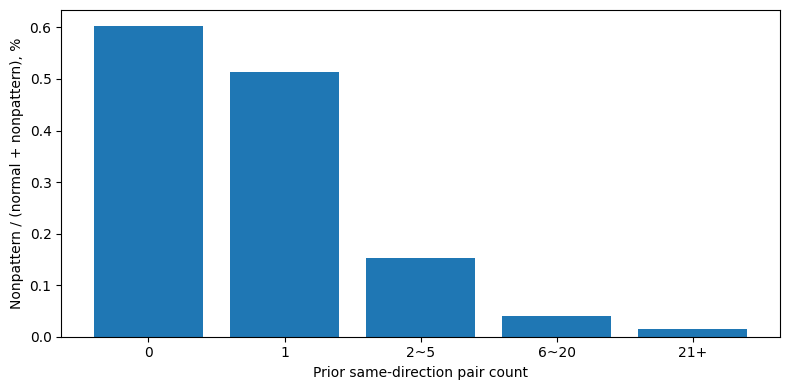

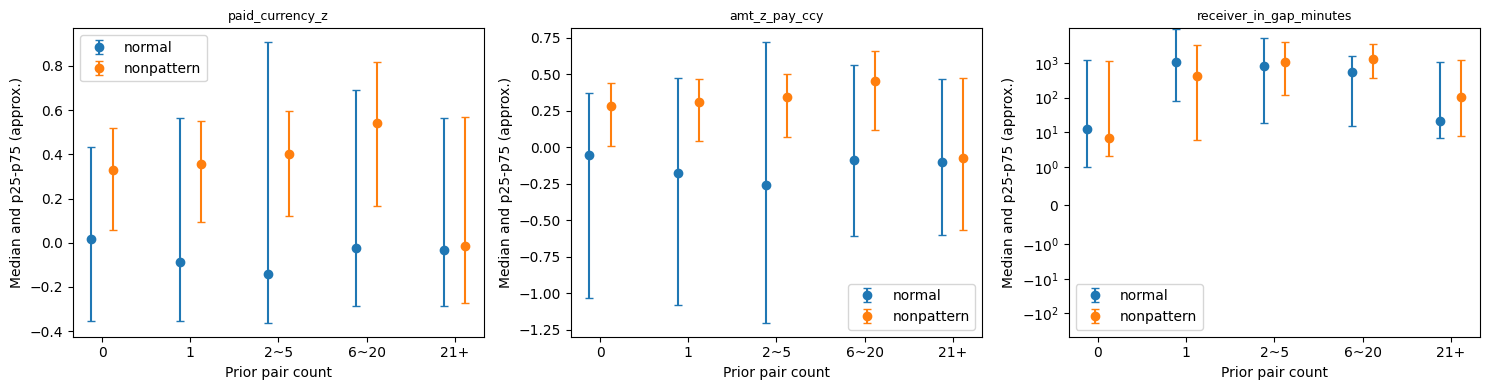

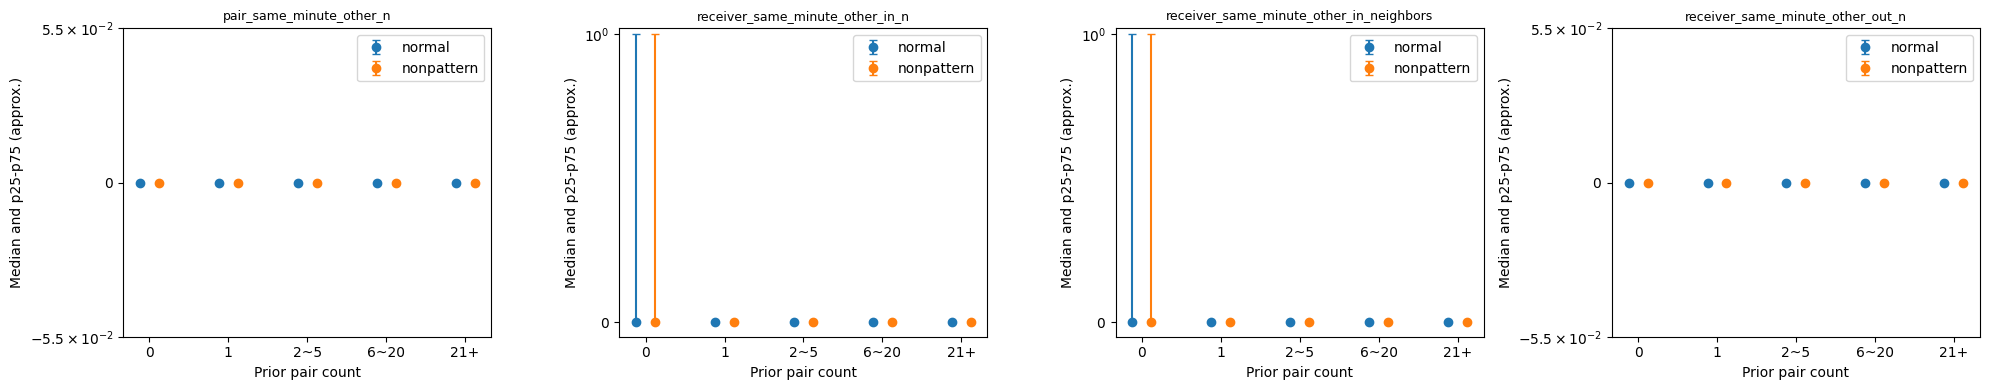

In [6]:
display(tables['feature_summary'].pivot(
    index=['prior_bucket_order','prior_bucket','feature'], columns='class_name', values='p50'))
with pd.option_context('display.max_rows', 120, 'display.max_columns', 20):
    display(tables['feature_summary'])
plot_results(tables, OUT)

## 6. 같은 분에 다른 거래가 많을수록 차이가 생기는가?

과거 이력 5개 구간 안에서 동일 분 활동도 0 / 1 / 2~5 / 6~20 / 21건 이상으로 나눕니다. 네 활동 피처의 표는 **서로 다른 분할**이므로 서로 합산하지 않습니다. `activity_bucket`은 현재 거래를 제외한 건수/고유 계좌 수의 구간입니다. 이 표의 무패턴 비율은 연관성이며, 해당 활동이 세탁의 원인이라는 뜻이 아닙니다.

In [7]:
with pd.option_context('display.max_rows', 120):
    for feature in MINUTE_METRICS:
        print(feature)
        view = tables['same_minute_rates'].query('feature == @feature').copy()
        view['nonpattern_pct'] = view.nonpattern_rate*100
        display(view[['prior_bucket','activity_bucket','normal_n','nonpattern_n',
                      'total_n','nonpattern_pct']])

pair_same_minute_other_n


,prior_bucket,activity_bucket,normal_n,nonpattern_n,total_n,nonpattern_pct
0,0,0,4467952,24534,4492486,0.546112
1,0,1,12274,2673,14947,17.883187
13,1,0,2698409,12764,2711173,0.470793
14,1,1,1240,1197,2437,49.117768
28,2~5,0,8545024,12442,8557466,0.145394
29,2~5,1,138579,902,139481,0.646683
30,2~5,2~5,1206,0,1206,0.000000
44,6~20,0,16582463,6856,16589319,0.041328
45,6~20,1,455321,134,455455,0.029421
46,6~20,2~5,5219,0,5219,0.000000


receiver_same_minute_other_in_n


,prior_bucket,activity_bucket,normal_n,nonpattern_n,total_n,nonpattern_pct
2,0,0,3290766,19745,3310511,0.596434
3,0,1,638787,4976,643763,0.772955
4,0,2~5,537763,2438,540201,0.451313
5,0,6~20,12910,48,12958,0.370428
15,1,0,2542608,11781,2554389,0.461206
16,1,1,114273,1839,116112,1.583816
17,1,2~5,42271,339,42610,0.795588
18,1,6~20,497,2,499,0.400802
31,2~5,0,8430172,12120,8442292,0.143563
32,2~5,1,237799,1132,238931,0.473777


receiver_same_minute_other_in_neighbors


,prior_bucket,activity_bucket,normal_n,nonpattern_n,total_n,nonpattern_pct
6,0,0,3290766,19745,3310511,0.596434
7,0,1,639407,4979,644386,0.772674
8,0,2~5,537232,2436,539668,0.451389
9,0,6~20,12821,47,12868,0.365247
19,1,0,2542608,11781,2554389,0.461206
20,1,1,114695,1840,116535,1.578925
21,1,2~5,41858,338,42196,0.801024
22,1,6~20,488,2,490,0.408163
35,2~5,0,8430172,12120,8442292,0.143563
36,2~5,1,240162,1134,241296,0.469962


receiver_same_minute_other_out_n


,prior_bucket,activity_bucket,normal_n,nonpattern_n,total_n,nonpattern_pct
10,0,0,4439007,27195,4466202,0.608907
11,0,1,40206,12,40218,0.029837
12,0,2~5,1013,0,1013,0.000000
23,1,0,2658566,13952,2672518,0.522054
24,1,1,33892,7,33899,0.020650
25,1,2~5,2089,0,2089,0.000000
26,1,6~20,1221,1,1222,0.081833
27,1,21+,3881,1,3882,0.025760
39,2~5,0,8464954,13332,8478286,0.157249
40,2~5,1,187636,7,187643,0.003730


## 7. 월별 관측 범위와 통화·결제 방식 구성 확인

월별 최초·최종 거래 시각과 거래가 존재하는 날짜 수를 실제 데이터로 확인합니다. `observed_days`는 거래가 있었던 날의 수이며 연속 기간 길이가 아닙니다. 분석 대상 거래만의 범위로, 전체 원장의 관측 범위와 다를 수 있습니다. 무패턴 행이 없는 월은 해당 클래스 행이 없습니다. 기본 설정에서 정상과 무패턴 모두 11월 1~5일만 포함하며, 11월 한 달 전체로 환산하지 않습니다. 12~1월은 이번 비교 대상에서 제외합니다.

통화·결제 방식별 건수표와 금액·입금 간격 분포를 같이 확인하세요. 여러 구성을 섞은 전체 차이가 각 구성 안에서도 유지되는지 보는 용도입니다. 희소 구간과 양성이 없는 구간에서 큰 차이를 과도하게 해석하지 않습니다.

In [8]:
display(tables['monthly_coverage'])
display(tables['monthly_bucket_rates'])
display(tables['monthly_feature_summary'])
display(tables['currency_format_bucket_rates'])
display(tables['currency_format_feature_summary'])
print('재사용 또는 생성한 원본 피처:', FEATURES)
print('표·그림 기간:', ANALYSIS_START, '~', ANALYSIS_END_EXCLUSIVE, '(종료 미포함)')
print('집계 CSV 8개 / 그림 PNG 3개 / 실행 정보:', OUT)

,month,class_name,n,first_ts,last_ts,observed_days
0,2022-08,nonpattern,19111,2022-08-08 00:01:00,2022-08-31 23:59:00,24
1,2022-08,normal,44496245,2022-08-08 00:00:00,2022-08-31 23:59:00,24
2,2022-09,nonpattern,27034,2022-09-01 00:00:00,2022-09-30 23:57:00,30
3,2022-09,normal,56069694,2022-09-01 00:00:00,2022-09-30 23:59:00,30
4,2022-10,nonpattern,30704,2022-10-01 00:02:00,2022-10-31 23:59:00,31
5,2022-10,normal,54746074,2022-10-01 00:00:00,2022-10-31 23:59:00,31
6,2022-11,nonpattern,5350,2022-11-01 00:00:00,2022-11-05 23:59:00,5
7,2022-11,normal,9222273,2022-11-01 00:00:00,2022-11-05 23:59:00,5


,month,prior_bucket_order,prior_bucket,total_n,normal_n,nonpattern_n,nonpattern_rate
0,2022-08,0,0,1486656,1477741,8915,0.005997
1,2022-08,1,1,1609681,1607127,2554,0.001587
2,2022-08,2,2~5,3397926,3396299,1627,0.000479
3,2022-08,3,6~20,8343994,8342392,1602,0.000192
4,2022-08,4,21+,29677099,29672686,4413,0.000149
5,2022-09,0,0,1503365,1494232,9133,0.006075
6,2022-09,1,1,468334,463477,4857,0.010371
7,2022-09,2,2~5,3564907,3561155,3752,0.001052
8,2022-09,3,6~20,4003080,4001016,2064,0.000516
9,2022-09,4,21+,46557042,46549814,7228,0.000155


,month,prior_bucket_order,prior_bucket,class_name,feature,n,valid_n,missing_n,mean,zero_rate_valid,p10,p25,p50,p75,p90,p99
0,2022-08,0,0,nonpattern,pair_prior_n,8915,8915,0,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,2022-08,0,0,nonpattern,paid_currency_z,8915,8915,0,0.428009,0.000000,-0.135690,0.102245,0.355905,0.537961,0.640884,4.657962
2,2022-08,0,0,nonpattern,amt_z_pay_ccy,8915,8915,0,0.288467,0.000000,-0.273362,0.049212,0.303977,0.453591,0.533138,3.187942
3,2022-08,0,0,nonpattern,receiver_in_gap_minutes,8915,8776,139,3806.444622,0.000000,1.000000,3.000000,15.000000,1839.000000,14964.000000,38309.000000
4,2022-08,0,0,nonpattern,receiver_in_count,8915,8915,0,17.364105,0.015592,2.000000,3.000000,8.000000,25.000000,47.000000,92.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,2022-11,4,21+,normal,pair_prior_n,8392774,8392774,0,187.807863,0.000000,93.000000,135.000000,187.000000,207.000000,287.000000,465.000000
196,2022-11,4,21+,normal,paid_currency_z,8392774,8392774,0,0.328138,0.000005,-0.348322,-0.280969,-0.019755,0.579620,1.431683,3.822527
197,2022-11,4,21+,normal,amt_z_pay_ccy,8392774,8392774,0,-0.003948,0.000000,-0.993235,-0.581705,-0.084382,0.478791,1.066921,2.599233
198,2022-11,4,21+,normal,receiver_in_gap_minutes,8392774,8392774,0,559.167550,0.000000,3.000000,7.000000,23.000000,1049.000000,1694.000000,2536.000000


,payment_currency,payment_format,prior_bucket_order,prior_bucket,total_n,normal_n,nonpattern_n,nonpattern_rate
0,Australian Dollar,ACH,0,0,70396,69722,674,0.009574
1,Australian Dollar,ACH,1,1,23090,22716,374,0.016197
2,Australian Dollar,ACH,2,2~5,27902,27550,352,0.012616
3,Australian Dollar,ACH,3,6~20,48184,48005,179,0.003715
4,Australian Dollar,ACH,4,21+,356421,356411,10,0.000028
...,...,...,...,...,...,...,...,...
436,Yuan,Wire,0,0,1,1,0,0.000000
437,Yuan,Wire,1,1,205,205,0,0.000000
438,Yuan,Wire,2,2~5,3883,3883,0,0.000000
439,Yuan,Wire,3,6~20,23420,23420,0,0.000000


,payment_currency,payment_format,prior_bucket_order,prior_bucket,class_name,feature,n,valid_n,missing_n,mean,zero_rate_valid,p10,p25,p50,p75,p90,p99
0,Australian Dollar,ACH,0,0,nonpattern,paid_currency_z,674,674,0,0.425841,0.0,-0.139868,0.071072,0.348321,0.521723,0.617464,6.294209
1,Australian Dollar,ACH,0,0,nonpattern,amt_z_pay_ccy,674,674,0,0.289744,0.0,-0.250044,0.037226,0.302684,0.442771,0.515376,4.112548
2,Australian Dollar,ACH,0,0,nonpattern,receiver_in_gap_minutes,674,668,6,3386.956587,0.0,1.000000,3.000000,10.000000,1448.000000,12449.000000,40798.000000
3,Australian Dollar,ACH,0,0,normal,paid_currency_z,69722,69722,0,0.376487,0.0,-0.144128,0.100680,0.358049,0.534285,0.619108,2.470126
4,Australian Dollar,ACH,0,0,normal,amt_z_pay_ccy,69722,69722,0,0.256586,0.0,-0.258421,0.069419,0.310904,0.452456,0.516600,1.727748
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1996,Yuan,Wire,3,6~20,normal,amt_z_pay_ccy,23420,23420,0,0.403761,0.0,-0.906295,-0.355412,0.327755,1.077836,1.829133,3.342893
1997,Yuan,Wire,3,6~20,normal,receiver_in_gap_minutes,23420,23420,0,815.359009,0.0,2.000000,5.000000,13.000000,675.000000,1816.000000,11879.000000
1998,Yuan,Wire,4,21+,normal,paid_currency_z,403283,403283,0,0.358811,0.0,-0.375110,-0.351886,-0.193874,0.629609,2.065169,4.091348
1999,Yuan,Wire,4,21+,normal,amt_z_pay_ccy,403283,403283,0,-0.206076,0.0,-1.621847,-1.022896,-0.338641,0.525803,1.459998,2.703031


재사용 또는 생성한 원본 피처: /workspace/money_laundry_ai_/parquets/HI-Large/nonpaten_vs_normal/pair_bins_same_minute_v1/features.parquet
표·그림 기간: 2022-08-08 ~ 2022-11-06 (종료 미포함)
집계 CSV 8개 / 그림 PNG 3개 / 실행 정보: /workspace/money_laundry_ai_/parquets/HI-Large/nonpaten_vs_normal/pair_bins_same_minute_until_1105


## 8. 해석할 때 확인할 내용

1. 반복 이력을 세분화했을 때도 무패턴 비율과 금액 z·입금 간격에 차이가 있는가?
2. 같은 이력 구간 안에서 동일 분 활동이 정상과 무패턴을 추가로 구분하는가?
3. 월별·통화·결제 방식 구성과 관측 기간 차이로 설명되는 부분은 없는가?
4. 차이가 있다면 다음 단계에서 시간 분리 평가로 확인한다. 현재 노트북은 분류 성능을 계산하지 않는다.

과거 피처만 사용하는 거래 직전 평가와 동일 분 활동까지 사용하는 분 종료 후 평가는 입력 가용 시점이 다르므로 별도 평가해야 합니다.